# 02 – Bivariate Analysis

## Credit Risk – Probability of Default

# 1. Libs

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
import numpy as np

from pathlib import Path
from IPython.display import display, HTML
from IPython.display import display_html
from ucimlrepo import fetch_ucirepo

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# 2. Data Loading

Loading the Default of Credit Card Clients dataset from the UCI Machine Learning Repository.

In [3]:
df = pd.read_parquet("../data/processed/credit_default_eda.parquet")

# 3. Payment Status vs. Credit Default

In [3]:
payment_status_columns = [
    "PAY_1", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

tables = []

for col in payment_status_columns:
    result = (
        df.groupby(col)["Y"]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "number_of_clients",
            "mean": "default_rate"
        })
    )

    result["default_rate"] *= 100

    output = widgets.Output(
        layout=widgets.Layout(width="300px")
    )

    with output:
        print(col)
        display(result.round(2))

    tables.append(output)

display(
    widgets.VBox(
        [
            widgets.HBox(tables[:3], layout=widgets.Layout(gap="30px")),
            widgets.HBox(tables[3:], layout=widgets.Layout(gap="30px"))
        ],
        layout=widgets.Layout(gap="30px")
    )
)

__We have now uncovered one of the most significant findings from our EDA: payment delinquency history is strongly associated with the probability of default.__

Consider PAY_0, which represents September 2005: customers with a value of 2 exhibit a default rate of 69.14%, compared to only 12.81% for those with a value of 0.

This represents a difference of 56.33 percentage points.

__This suggests that recent payment delinquency history may be among the most relevant pieces of information for the model.__

__And this pattern persists across other time periods.__

There is a strong and consistent association between the code 2 and high default rates.

We also observe that the contrast between codes 0 and 2 is most pronounced in the most recent period (PAY_0).

This aligns with the hypothesis that recent delinquencies carry more predictive information regarding default in the following month. However, we cannot yet conclude that PAY_0 will necessarily be the most important variable in the model.

__A note of caution regarding rare categories__

Consider a few examples:

- PAY_3 = 1: only 4 customers.
- PAY_4 = 1: only 2 customers.
- PAY_5 = 8: only 1 customer.
- PAY_6 = 8: only 2 customers.

A 100% default rate within a group of only two customers does not imply that all future customers with this characteristic will default.

We should not interpret extreme rates from very small groups as reliable risk estimates.

__But, reggarding our model, we already have exploratory evidence that payment history contains a significant predictive signal.__

However, we still need to determine how to represent these variables:

- Keep them as integers.
- Treat them as categories.
- Create derived variables, such as the number of periods with delinquencies.

__We do not need to decide this just yet. We can compare different representations during modeling.__

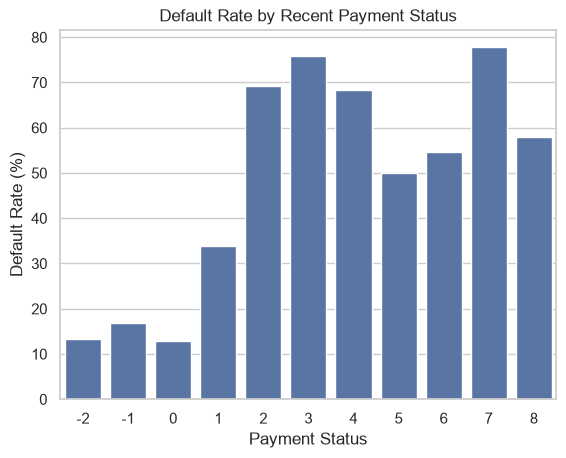

In [6]:
payment_default_rates = (
    df.groupby("PAY_1")["Y"]
      .agg(["count", "mean"])
      .reset_index()
)

payment_default_rates["mean"] *= 100

sns.barplot(
    data=payment_default_rates,
    x="PAY_1",
    y="mean"
)

plt.title("Default Rate by Recent Payment Status")
plt.xlabel("Payment Status")
plt.ylabel("Default Rate (%)")
plt.show()

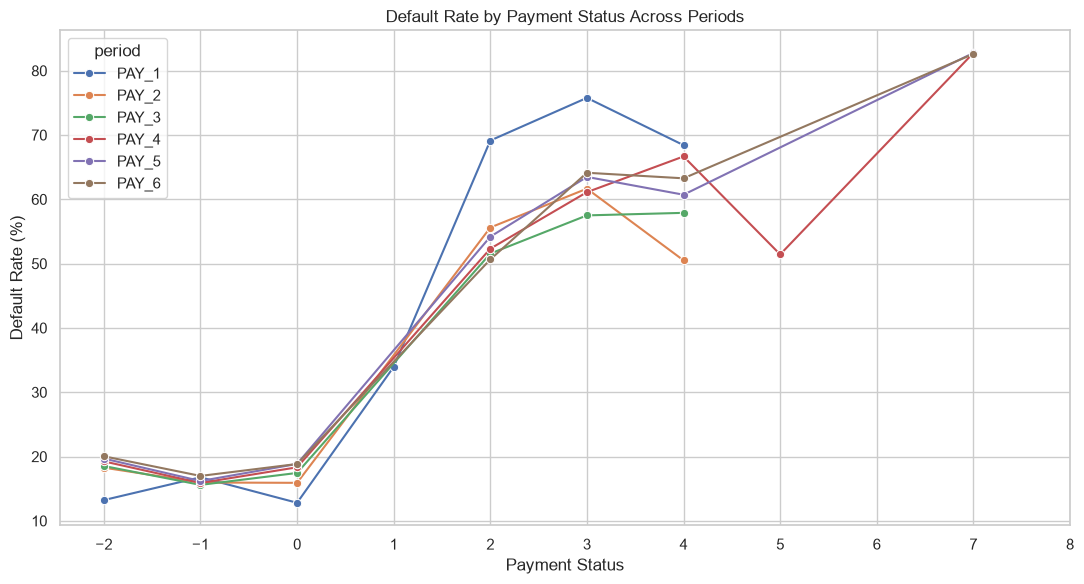

In [7]:
payment_status_columns = [
    "PAY_1", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

results = []

for col in payment_status_columns:
    rates = (
        df.groupby(col)["Y"]
        .agg(["count", "mean"])
        .reset_index()
        .rename(columns={
            col: "payment_status",
            "count": "number_of_clients",
            "mean": "default_rate"
        })
    )

    rates["period"] = col
    rates["default_rate"] *= 100

    results.append(rates)

payment_rates = pd.concat(results, ignore_index=True)

# Focus on categories with at least 30 observations
plot_data = payment_rates[
    payment_rates["number_of_clients"] >= 30
]

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=plot_data,
    x="payment_status",
    y="default_rate",
    hue="period",
    marker="o"
)

plt.title("Default Rate by Payment Status Across Periods")
plt.xlabel("Payment Status")
plt.ylabel("Default Rate (%)")
plt.xticks(range(-2, 9))
plt.tight_layout()
plt.show()

__Payment status variables exhibit a strong association with credit default.__ 

Default rates increase substantially for delinquency codes of 2 or higher, particularly in the most recent period (PAY_0). Special codes (-2, -1, 0) do not exhibit a clear ordinal relationship, while rare delinquency categories produce unstable default-rate estimates.

In [10]:
transition_matrix = pd.crosstab(
    df["PAY_2"],
    df["PAY_1"]
)

display(transition_matrix)

PAY_1,-2,-1,0,1,2,3,4,5,6,7,8
PAY_2,,,,,,,,,,,
-2,2561,0,0,1221,0,0,0,0,0,0,0
-1,193,4641,478,612,126,0,0,0,0,0,0
0,0,603,14259,3,865,0,0,0,0,0,0
1,0,0,0,28,0,0,0,0,0,0,0
2,5,387,0,1672,1591,272,0,0,0,0,0
3,0,47,0,109,71,41,58,0,0,0,0
4,0,5,0,32,14,8,15,25,0,0,0
5,0,3,0,7,0,1,3,0,11,0,0
6,0,0,0,2,0,0,0,1,0,9,0


__The transition matrix provides strong empirical evidence that positive payment status codes represent consecutive months of payment delay.__ 

The observed transitions from codes 2→3, 3→4, 4→5, and subsequent levels are consistent with the accumulation of delinquency over consecutive billing periods. However, these transitions do not necessarily imply a complete absence of payments, as partial payments may occur while an account remains delinquent.

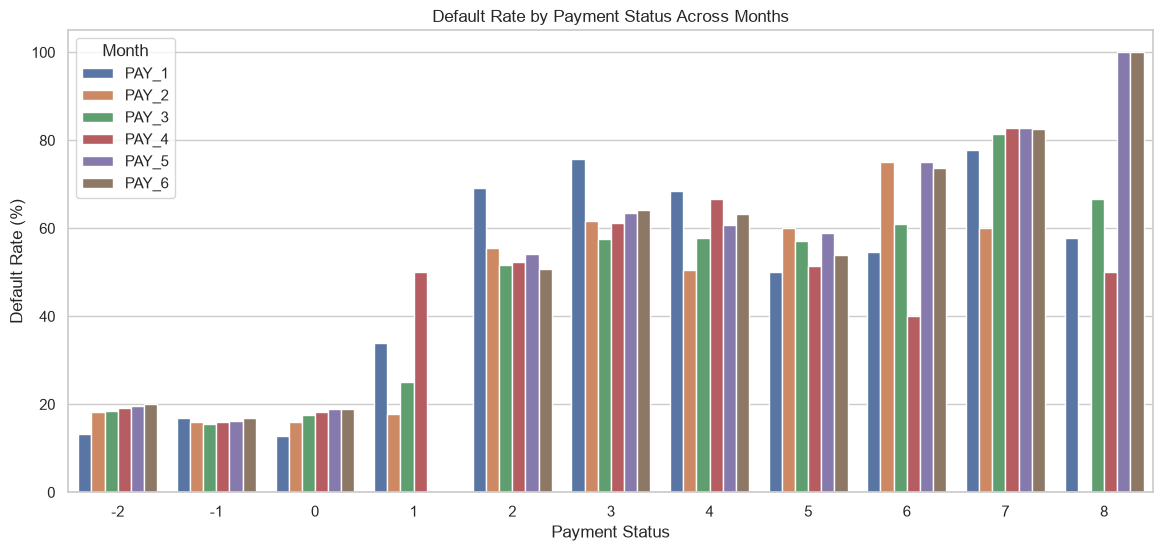

In [11]:
payment_columns = ["PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]

payment_default_rates = (
    df.melt(
        id_vars="Y",
        value_vars=payment_columns,
        var_name="Month",
        value_name="Payment_Status"
    )
    .groupby(["Month", "Payment_Status"])["Y"]
    .agg(["count", "mean"])
    .reset_index()
)

payment_default_rates["mean"] *= 100

plt.figure(figsize=(14, 6))

sns.barplot(
    data=payment_default_rates,
    x="Payment_Status",
    y="mean",
    hue="Month"
)

plt.title("Default Rate by Payment Status Across Months")
plt.xlabel("Payment Status")
plt.ylabel("Default Rate (%)")
plt.legend(title="Month")
plt.show()

# 4. Demographic Variables vs. Credit Default

In [16]:
import ipywidgets as widgets
from IPython.display import display

demographic_columns = ["EDUCATION", "MARRIAGE", "SEX"]

outputs = []

for col in demographic_columns:

    output = widgets.Output()

    with output:
        result = (
            df.groupby(col)["Y"]
            .agg(["count", "mean"])
            .rename(columns={
                "count": "number_of_clients",
                "mean": "default_rate"
            })
        )

        result["default_rate"] *= 100

        print(col)
        display(result.round(2))

    outputs.append(output)

# Display all three tables side by side
display(widgets.HBox(
    outputs,
    layout=widgets.Layout(
        width="100%",
        justify_content="space-between",
        gap="20px"
    )
))

__Key Findings — Demographic Variables vs. Credit Default__

__Education__

Default rates increase from graduate school (19.23%) to university (23.73%) and high school (25.16%).

Undocumented categories (0, 5, 6) are present and will be investigated during preprocessing.

Categories with small sample sizes require cautious interpretation.

__Marital Status__

Married clients exhibit a higher default rate (23.47%) than single clients (20.93%).

Category 0 is undocumented and contains only 54 observations.

__Sex__

Male clients exhibit a default rate of 24.17%, compared with 20.78% for female clients.

Sex is a sensitive demographic characteristic and requires fairness and regulatory considerations before inclusion in a credit decision model.

Preprocessing Considerations

Preserve observations with undocumented categories.

Consider grouping undocumented codes into an Unknown category.

Evaluate categorical encoding strategies during model development.

Avoid using observed default rates alone to determine category groupings.

__Conclusion__

__Demographic variables exhibit associations with credit default. However, these relationships do not establish causality or automatically justify their use in credit decision-making.__

# 5. Default Rate vs. Credit Limit

In [17]:
limit_bins = pd.qcut(
    df["LIMIT_BAL"],
    q=10,
    duplicates="drop"
)

result = (
    df.groupby(limit_bins, observed=True)["Y"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "number_of_clients",
        "mean": "default_rate"
    })
)

result["default_rate"] *= 100

display(result.round(2))

,number_of_clients,default_rate
LIMIT_BAL,,
"(9999.999, 30000.0]",4081,35.85
"(30000.0, 50000.0]",3595,27.18
"(50000.0, 70000.0]",1556,28.47
"(70000.0, 100000.0]",3266,24.53
"(100000.0, 140000.0]",2792,22.85
"(140000.0, 180000.0]",3331,17.35
"(180000.0, 210000.0]",2487,17.53
"(210000.0, 270000.0]",2934,16.29
"(270000.0, 360000.0]",3482,15.16


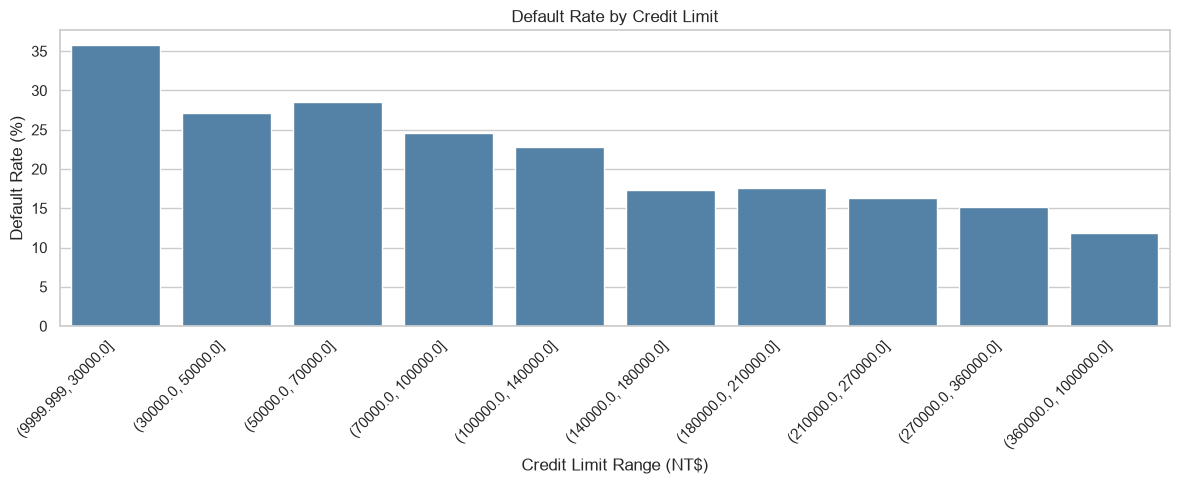

In [18]:
plot_data = result.reset_index()

plt.figure(figsize=(12, 5))

sns.barplot(
    data=plot_data,
    x="LIMIT_BAL",
    y="default_rate",
    color="steelblue"
)

plt.title("Default Rate by Credit Limit")
plt.xlabel("Credit Limit Range (NT$)")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

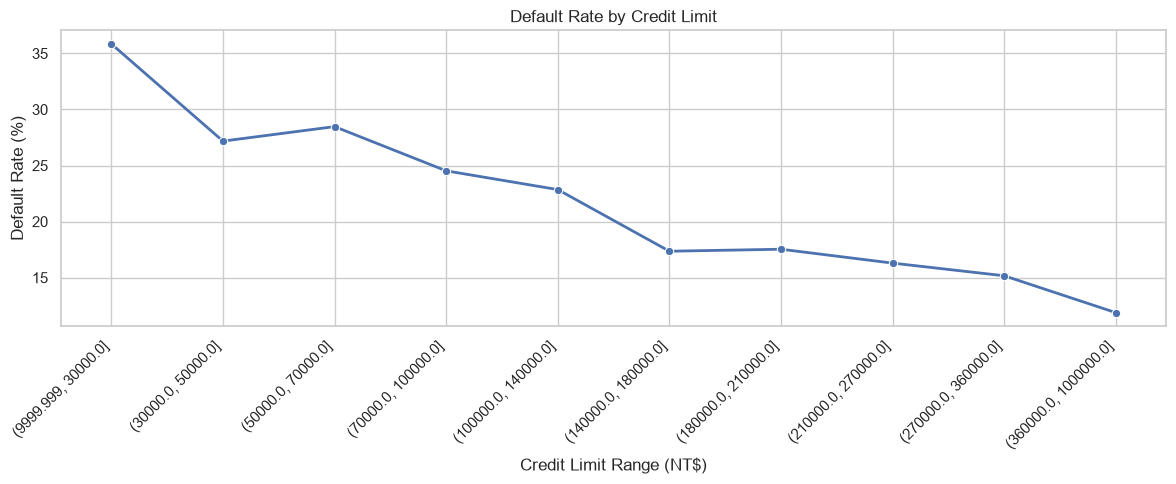

In [22]:
plot_data = result.reset_index()

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=plot_data,
    x=range(len(plot_data)),
    y="default_rate",
    marker="o",
    linewidth=2
)

plt.xticks(
    ticks=range(len(plot_data)),
    labels=plot_data["LIMIT_BAL"].astype(str),
    rotation=45,
    ha="right"
)

plt.title("Default Rate by Credit Limit")
plt.xlabel("Credit Limit Range (NT$)")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()

__Credit limit (LIMIT_BAL) exhibits a strong inverse association with credit default.__

Clients with credit limits between NT$10,000 and NT$30,000 have the highest observed default rate (35.85%).

Clients with credit limits above NT$360,000 have the lowest observed default rate (11.87%).

The difference between these groups is approximately 24 percentage points.

The relationship is predominantly decreasing, although minor fluctuations occur across credit limit ranges.

This association does not imply causation, as credit limits may reflect prior creditworthiness assessments.

__Modeling decision: Retain LIMIT_BAL as a continuous numerical variable. Quantile-based binning was used exclusively for exploratory analysis. No transformation is required at this stage.__

# 6. AGE vs. Credit Default

In [19]:
age_bins = pd.qcut(
    df["AGE"],
    q=10,
    duplicates="drop"
)

age_result = (
    df.groupby(age_bins, observed=True)["Y"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "number_of_clients",
        "mean": "default_rate"
    })
)

age_result["default_rate"] *= 100

display(age_result.round(2))

,number_of_clients,default_rate
AGE,,
"(20.999, 25.0]",3871,26.66
"(25.0, 27.0]",2733,20.71
"(27.0, 29.0]",3014,19.87
"(29.0, 31.0]",2612,19.26
"(31.0, 34.0]",3466,19.36
"(34.0, 37.0]",3262,21.74
"(37.0, 40.0]",2768,20.95
"(40.0, 43.0]",2288,22.73
"(43.0, 49.0]",3306,23.53


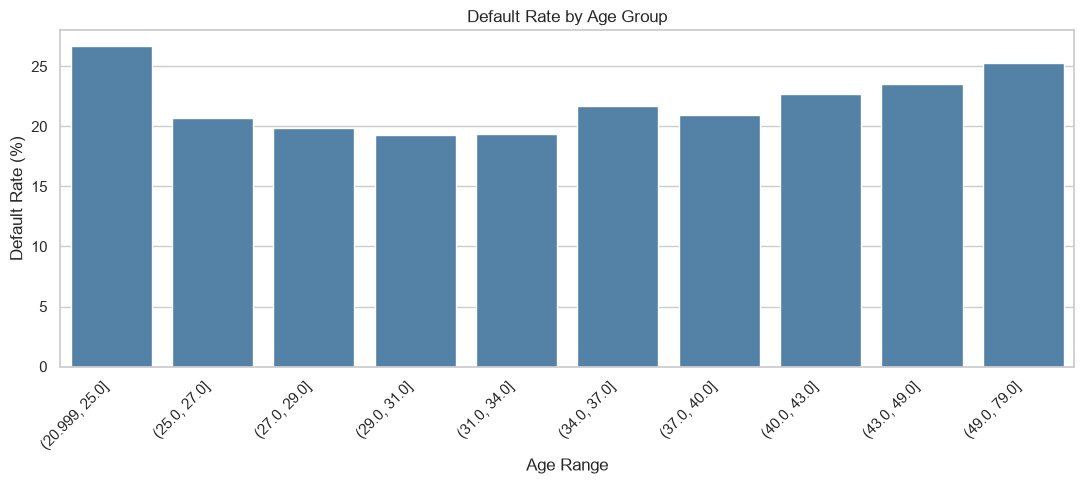

In [20]:
plot_data = age_result.reset_index()

plt.figure(figsize=(11, 5))

sns.barplot(
    data=plot_data,
    x="AGE",
    y="default_rate",
    color="steelblue"
)

plt.title("Default Rate by Age Group")
plt.xlabel("Age Range")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

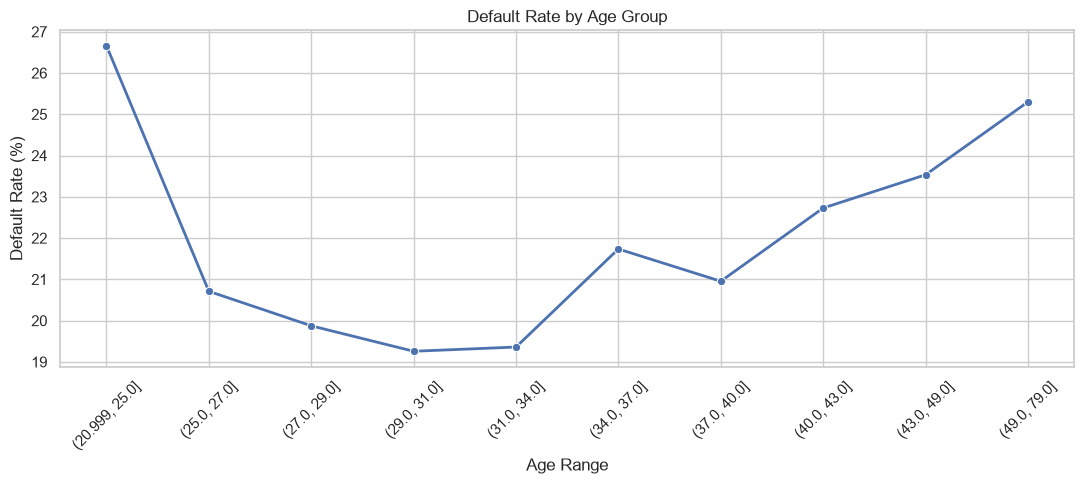

In [21]:
plot_data = age_result.reset_index()

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=plot_data,
    x=range(len(plot_data)),
    y="default_rate",
    marker="o",
    linewidth=2
)

plt.xticks(
    ticks=range(len(plot_data)),
    labels=plot_data["AGE"].astype(str),
    rotation=45
)

plt.title("Default Rate by Age Group")
plt.xlabel("Age Range")
plt.ylabel("Default Rate (%)")

plt.tight_layout()
plt.show()

__Findings__

- The relationship between age and credit default exhibits an approximately U-shaped pattern.
- Younger clients (21–25 years) have the highest observed default rate (26.66%).
- Clients aged 30–31 have the lowest observed default rate (19.26%).
- Default rates increase again among older clients, reaching 25.30% for the 50–79 age group.
- The difference between the highest and lowest observed default rates is 7.40 percentage points.
- These findings suggest a nonlinear association between age and default, but do not establish causality.
- AGE will remain a numerical variable during initial modeling. Nonlinear effects can be evaluated through tree-based models or appropriate transformations.
- The use of age in operational credit decisions requires fairness and regulatory considerations.

# 7. Bill Amount vs. Credit Default

In [12]:
left = widgets.Output()
right = widgets.Output()

# Calculate default rate by bill status
bill_groups = np.select(
    [
        df["BILL_AMT1"] < 0,
        df["BILL_AMT1"] == 0,
        df["BILL_AMT1"] > 0
    ],
    [
        "Negative",
        "Zero",
        "Positive"
    ],
    default="Unknown"
)

result = (
    df.assign(BILL_GROUP=bill_groups)
      .groupby("BILL_GROUP")["Y"]
      .agg(["count", "mean"])
      .rename(columns={
          "count": "number_of_clients",
          "mean": "default_rate"
      })
)

result["default_rate"] *= 100

# Table output
with left:
    display(result.round(2))

# Chart output
with right:
    plt.figure(figsize=(6, 4))

    ax = sns.barplot(
        data=result.reset_index(),
        x="BILL_GROUP",
        y="default_rate",
        color="steelblue"
    )

    ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)

    plt.title("Default Rate by Bill Amount Status")
    plt.xlabel("Bill Amount Status")
    plt.ylabel("Default Rate (%)")
    plt.ylim(0, 32)

    plt.tight_layout()
    plt.show()

# Display table and chart side by side
display(widgets.HBox([left, right]))

__Bill Amount Status — Key Findings__

- Clients with zero bill amounts exhibit a higher default
  rate (26.59%) than clients with positive (21.87%) or
  negative (18.47%) bill amounts.
- Zero and negative bill amounts may carry distinct
  predictive information.
- Original bill amounts will be preserved.
- The number of periods with zero bill amounts may be
  evaluated as a candidate engineered feature.
- These associations do not establish causality.

In [13]:
# Select clients with positive bill amounts
positive_bills = df[df["BILL_AMT1"] > 0].copy()

# Create quantile-based intervals
bill_bins = pd.qcut(
    positive_bills["BILL_AMT1"],
    q=10,
    duplicates="drop"
)

# Calculate default rate by bill amount range
bill_result = (
    positive_bills.groupby(bill_bins, observed=True)["Y"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "number_of_clients",
        "mean": "default_rate"
    })
)

bill_result["default_rate"] *= 100

# Create output widgets
left = widgets.Output()
right = widgets.Output()

# Display table
with left:
    display(bill_result.round(2))

# Display chart
with right:
    plt.figure(figsize=(8, 5))

    plt.plot(
        range(1, len(bill_result) + 1),
        bill_result["default_rate"],
        marker="o"
    )

    # Overall default rate as reference
    plt.axhline(
        df["Y"].mean() * 100,
        color="red",
        linestyle="--",
        label="Overall Default Rate"
    )

    plt.title("Default Rate by Positive Bill Amount")
    plt.xlabel("Quantile Group")
    plt.ylabel("Default Rate (%)")
    plt.xticks(range(1, len(bill_result) + 1))
    plt.ylim(0, 35)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Display table and chart side by side
display(widgets.HBox([left, right]))

__Positive Bill Amounts — Key Findings__

- Positive bill amounts exhibit no clear monotonic
  relationship with credit default.
- Default rates range from 18.72% to 24.50% across
  quantile-based intervals.
- Absolute bill amounts may provide limited standalone
  discriminatory information.
- Credit utilization will be evaluated as a candidate
  engineered feature.
- Original bill amount variables will be preserved
  during initial modeling.

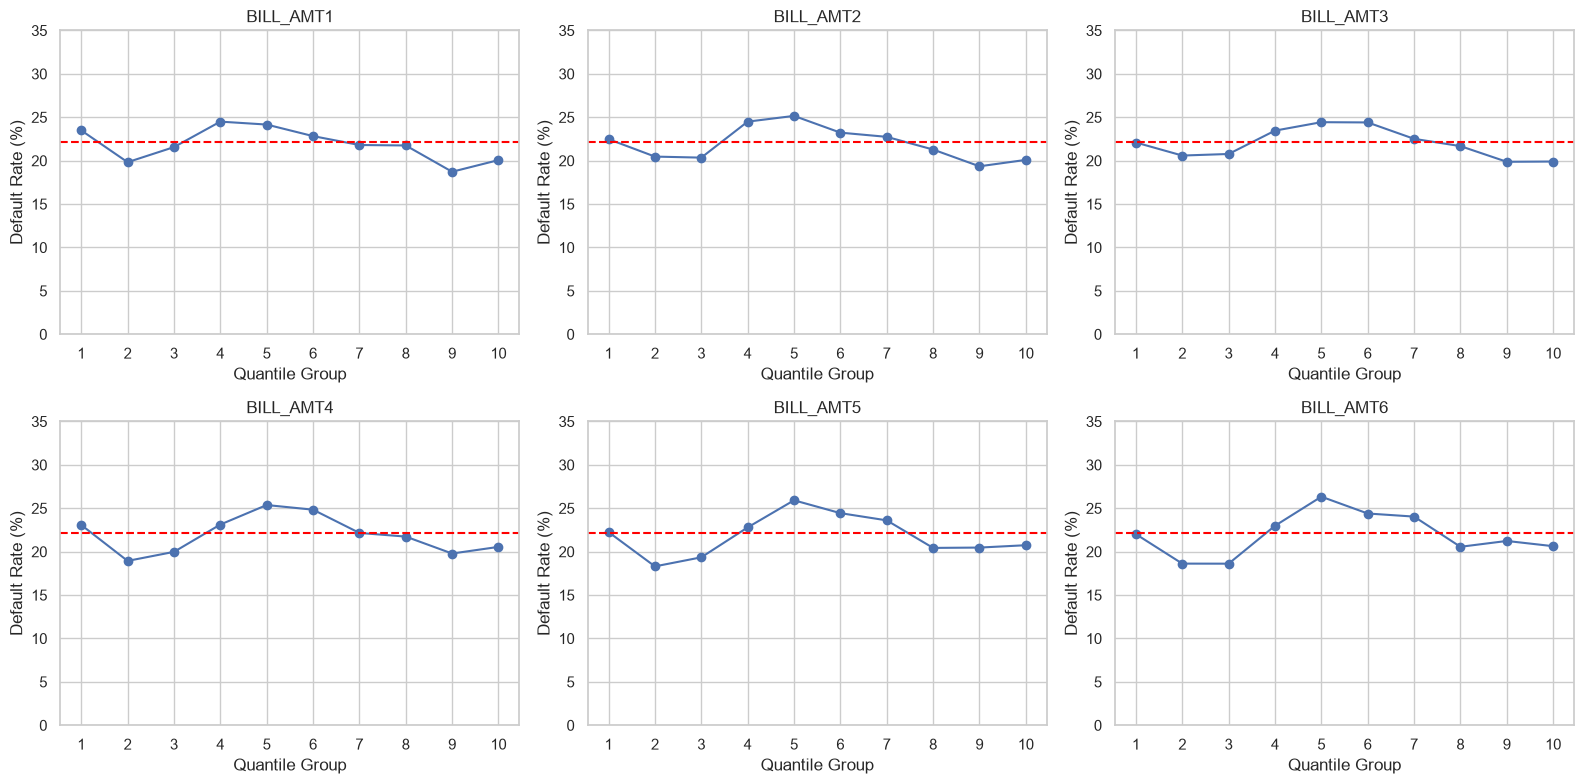

In [14]:
bill_columns = [f"BILL_AMT{i}" for i in range(1, 7)]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, col in zip(axes.flat, bill_columns):

    # Select positive bill amounts
    positive = df[df[col] > 0]

    # Create quantile-based intervals
    bins = pd.qcut(
        positive[col],
        q=10,
        duplicates="drop"
    )

    # Calculate default rate per interval
    rates = (
        positive.groupby(bins, observed=True)["Y"]
        .mean() * 100
    )

    ax.plot(
        range(1, len(rates) + 1),
        rates.values,
        marker="o"
    )

    # Overall default rate as reference
    ax.axhline(
        df["Y"].mean() * 100,
        color="red",
        linestyle="--"
    )

    ax.set_title(col)
    ax.set_xlabel("Quantile Group")
    ax.set_ylabel("Default Rate (%)")
    ax.set_xticks(range(1, len(rates) + 1))
    ax.set_ylim(0, 35)

plt.tight_layout()
plt.show()

__Bill Amounts Across Periods — Key Findings__

- The visible billing periods exhibit similar
  non-monotonic relationships with credit default.
- Intermediate bill amount quantiles tend to exhibit
  higher default rates.
- Higher bill amount quantiles generally exhibit
  lower default rates.
- Potential redundancy across billing periods will
  be investigated through correlation analysis.
- Original bill amount variables will be preserved
  during initial modeling.
- Credit utilization, average bill amount and balance
  trends will be evaluated as candidate engineered
  features.

# 8. Payment Amount vs. Credit Default

Zero vs. Positive Payments

In [17]:
import ipywidgets as widgets

# Reshape data for visualization
payment_plot = (
    payment_summary
    .rename_axis("payment_status")
    .reset_index()
    .pivot(
        index="variable",
        columns="payment_status",
        values="default_rate"
    )
)

# Create output containers
table_output = widgets.Output()
plot_output = widgets.Output()

# Display summary table
with table_output:
    display(payment_summary.round(2))

# Display default rates across payment periods
with plot_output:
    fig, ax = plt.subplots(figsize=(7, 5))

    ax.plot(
        payment_plot.index,
        payment_plot["Zero"],
        marker="o",
        label="Zero Payment"
    )

    ax.plot(
        payment_plot.index,
        payment_plot["Positive"],
        marker="o",
        label="Positive Payment"
    )

    # Overall default rate as reference
    ax.axhline(
        df["Y"].mean() * 100,
        color="red",
        linestyle="--",
        label="Overall Default Rate"
    )

    ax.set_title("Default Rate by Payment Status")
    ax.set_xlabel("Payment Period")
    ax.set_ylabel("Default Rate (%)")
    ax.set_ylim(0, 40)
    ax.legend()

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Display table and chart side by side
display(widgets.HBox([table_output, plot_output]))

__Zero vs. Positive Payments — Key Findings__

- Zero payments are associated with higher default
  rates across all six periods.
- The most recent zero payment exhibits the strongest
  association with default (35.95% vs. 19.19%).
- The default rate gap decreases for older periods,
  suggesting that payment recency may be relevant.
- Clients with positive payments exhibit relatively
  stable default rates across periods.
- Zero payment frequency, recency and consecutive
  zero payments will be evaluated as candidate
  engineered features.
- Zero payments do not necessarily indicate delinquency,
  as clients may have no outstanding balance.

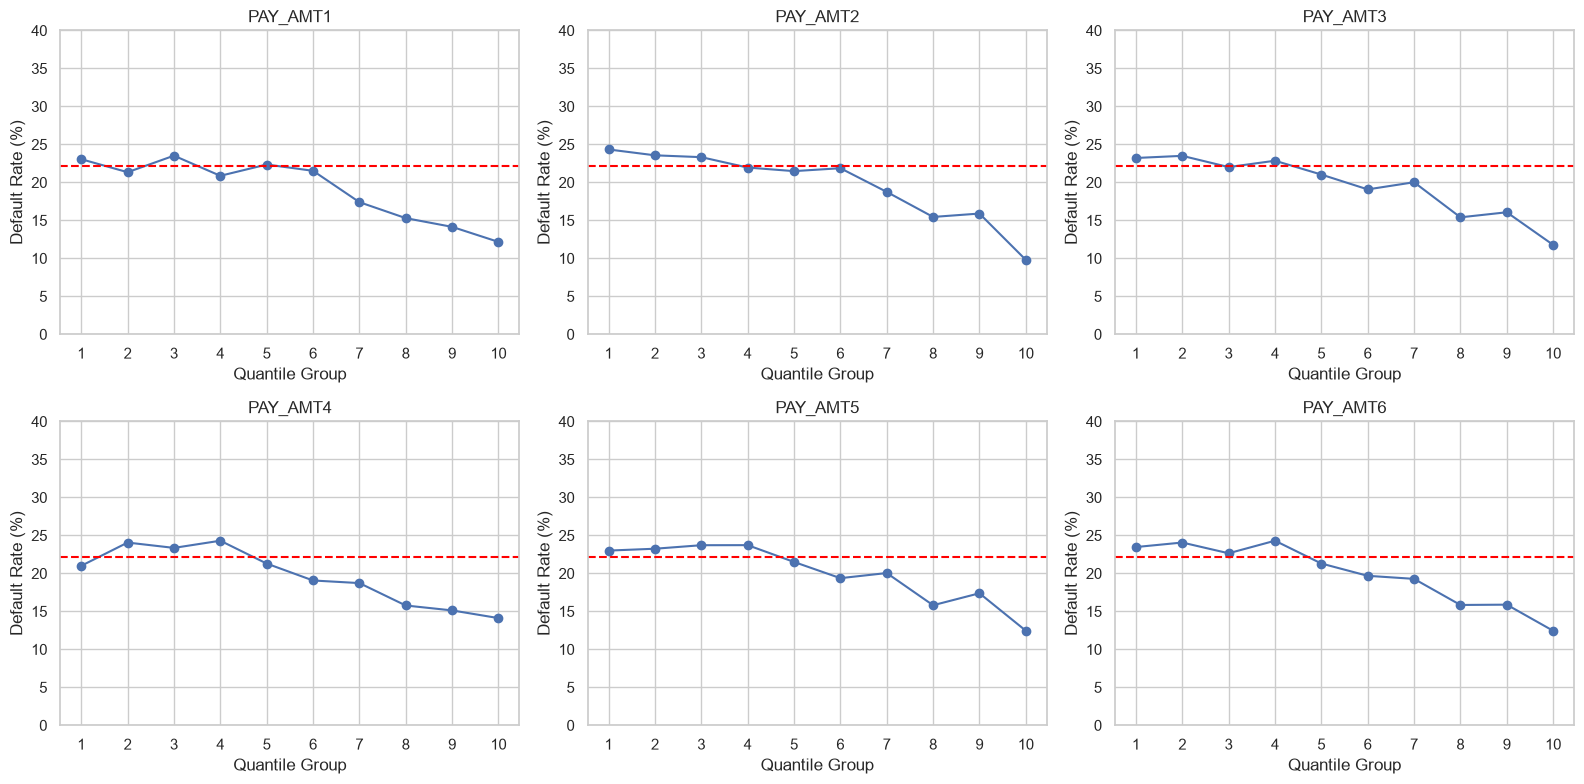

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, col in zip(axes.flat, payment_columns):

    # Select positive payment amounts
    positive = df[df[col] > 0]

    # Create quantile-based intervals
    bins = pd.qcut(
        positive[col],
        q=10,
        duplicates="drop"
    )

    # Calculate default rate per interval
    rates = (
        positive.groupby(bins, observed=True)["Y"]
        .mean() * 100
    )

    ax.plot(
        range(1, len(rates) + 1),
        rates.values,
        marker="o"
    )

    # Overall default rate as reference
    ax.axhline(
        df["Y"].mean() * 100,
        color="red",
        linestyle="--"
    )

    ax.set_title(col)
    ax.set_xlabel("Quantile Group")
    ax.set_ylabel("Default Rate (%)")
    ax.set_xticks(range(1, len(rates) + 1))
    ax.set_ylim(0, 40)

plt.tight_layout()
plt.show()

__Positive Payment Amounts — Key Findings__

- Higher positive payment amounts are generally
  associated with lower default rates.
- The relationship is predominantly decreasing
  but not strictly monotonic or linear.
- This pattern is consistent across all six periods.
- Both payment absence and payment magnitude
  may provide predictive information.
- Original payment amount variables will be preserved.
- Payment frequency, magnitude, recency and
  payment-to-bill ratios will be evaluated as
  candidate engineered features.

# 9. Correlation and Redundancy Analysis

## Pearson Correlation

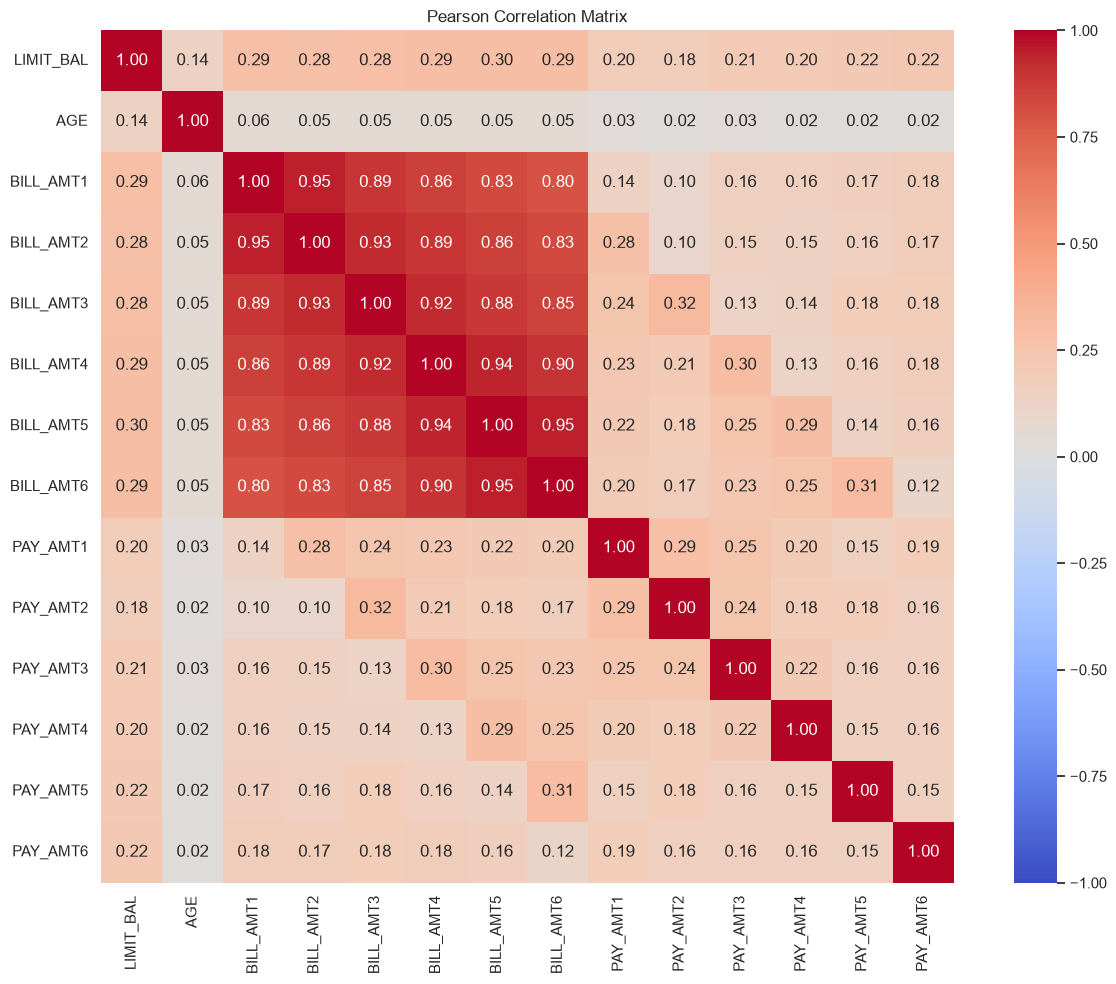

In [19]:
# Select quantitative variables
numerical_columns = (
    ["LIMIT_BAL", "AGE"]
    + [f"BILL_AMT{i}" for i in range(1, 7)]
    + [f"PAY_AMT{i}" for i in range(1, 7)]
)

# Calculate Pearson correlation
pearson_corr = df[numerical_columns].corr(
    method="pearson"
)

# Visualize the correlation matrix
plt.figure(figsize=(13, 10))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

__Pearson Correlation — Key Findings__

- Bill amount variables exhibit strong positive
  correlations, ranging from 0.80 to 0.95.
- Correlations tend to decrease as the distance
  between billing periods increases.
- Payment amount variables exhibit relatively
  weak linear correlations with each other.
- Age exhibits negligible linear correlations
  with financial variables.
- Strong correlations among bill amounts may
  introduce multicollinearity in logistic regression.
- Aggregated billing features will be evaluated
  as potential alternatives to redundant variables.
- No variables will be removed solely based on
  Pearson correlation.

## Spearman Correlation

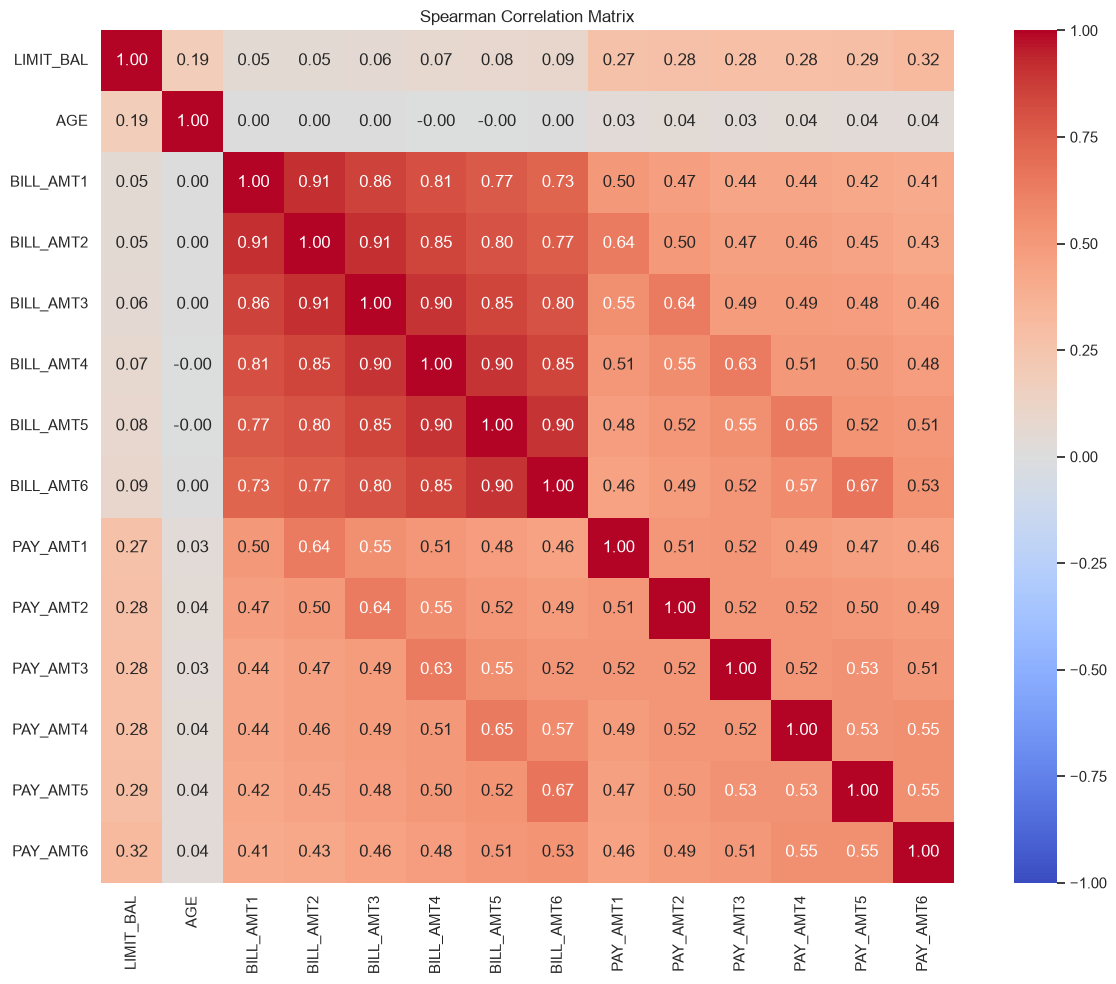

In [21]:
# Calculate Spearman correlation
spearman_corr = df[numerical_columns].corr(
    method="spearman"
)

# Visualize the correlation matrix
plt.figure(figsize=(13, 10))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()

__Spearman Correlation — Key Findings__

- Bill amount variables remain strongly correlated,
  reinforcing the hypothesis of feature redundancy.
- Payment amount variables exhibit moderate rank
  correlations despite weak Pearson correlations.
- Associations between bill and payment amounts
  are stronger under Spearman correlation.
- Credit limit exhibits weak rank correlations
  with bill amounts.
- Differences between Pearson and Spearman may
  reflect skewness, extreme values or nonlinear
  relationships.
- Strong associations between payments and previous
  billing periods suggest that temporal alignment
  should be considered during feature engineering.
- No variables will be removed solely based on
  correlation analysis.

## Cramér's V Association Matrix

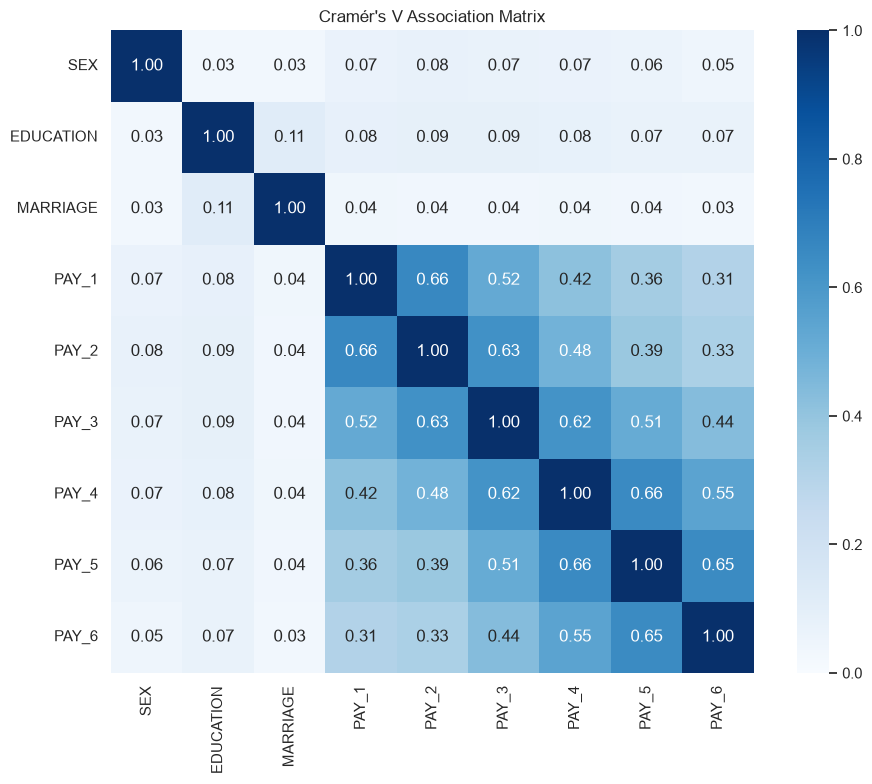

In [22]:
from scipy.stats.contingency import association

# Select categorical variables
categorical_columns = (
    ["SEX", "EDUCATION", "MARRIAGE"]
    + [f"PAY_{i}" for i in range(1, 7)]
)

# Initialize association matrix
cramers_matrix = pd.DataFrame(
    index=categorical_columns,
    columns=categorical_columns,
    dtype=float
)

# Calculate Cramér's V for each variable pair
for col1 in categorical_columns:
    for col2 in categorical_columns:

        contingency_table = pd.crosstab(
            df[col1],
            df[col2]
        )

        cramers_matrix.loc[col1, col2] = association(
            contingency_table,
            method="cramer"
        )

# Visualize the association matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cramers_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    square=True
)

plt.title("Cramér's V Association Matrix")
plt.tight_layout()
plt.show()

__Cramér's V — Key Findings__

- Payment status variables exhibit relatively strong
  associations between consecutive periods.
- Associations decrease as the temporal distance
  between periods increases.
- Demographic variables exhibit weak associations
  with each other and with payment status variables.
- Historical payment status variables may provide
  complementary predictive information.
- Aggregated delinquency features will be evaluated
  during feature engineering.
- No categorical variables will be removed solely
  based on Cramér's V.

# 10. Exploratory Data Analysis — Final Conclusions.

### Main Findings

- Payment status exhibits a strong association with
  credit default, particularly in recent periods.
- Higher credit limits are generally associated with
  lower default rates.
- Age exhibits a nonlinear relationship with default.
- Absolute bill amounts exhibit relatively weak and
  non-monotonic relationships with default.
- Zero payments are consistently associated with
  higher default rates.
- Higher positive payment amounts are generally
  associated with lower default rates.
- Bill amount variables exhibit strong redundancy.
- Payment amounts exhibit moderate rank correlations.
- Payment status associations decrease with temporal
  distance.
- Undocumented categorical codes require explicit
  preprocessing decisions.

### Modeling Strategy

- Preserve original predictors for baseline modeling.
- Evaluate alternative categorical encoding strategies.
- Engineer behavioral and financial ratio features.
- Investigate feature redundancy and multicollinearity.
- Compare baseline, engineered and reduced feature sets.
- Evaluate demographic feature inclusion from predictive
  and fairness perspectives.
- Perform data-dependent preprocessing and feature
  selection using training data only.

### Limitations

- Exploratory associations do not establish causality.
- Feature importance cannot be determined solely
  through bivariate analysis.
- Target-based exploratory analysis was performed
  before the train-test split, limiting the independence
  of subsequent holdout evaluation.

### Next Steps

Proceed to feature engineering, preprocessing,
model training and validation.

__Decisões sobre as variáveis originais__

| Variável | Decisão inicial | Transformação candidata |
|---|---|---|
| LIMIT_BAL | Manter | Scaling |
| AGE | Manter experimentalmente | Transformação não linear |
| SEX | Avaliar inclusão | OHE |
| EDUCATION | Manter experimentalmente | Agrupamento de códigos desconhecidos + OHE |
| MARRIAGE | Manter experimentalmente | Tratamento do código 0 + OHE |
| PAY_1 a PAY_6 | Manter | Comparar codificações |
| BILL_AMT1 a BILL_AMT6 | Manter inicialmente | Agregação e redução de redundância |
| PAY_AMT1 a PAY_AMT6 | Manter | log1p e scaling, quando apropriado |

__As variáveis demográficas também serão avaliadas sob a perspectiva de equidade e conformidade regulatória.__

---

__Features que construiremos__

Estas são as features candidatas que nossa EDA ajudou a justificar.

**Histórico de atrasos**

| Feature | Justificativa |
|---|---|
| MAX_DELAY | Severidade máxima do atraso |
| AVG_DELAY | Severidade média dos atrasos |
| DELAY_COUNT | Frequência de atrasos |
| CONSECUTIVE_DELAYS | Persistência recente dos atrasos |
| DELAY_TREND | Evolução do comportamento de atraso |

**Faturas**

| Feature | Justificativa |
|---|---|
| AVG_BILL | Redundância entre períodos |
| MAX_BILL | Exposição máxima observada |
| BILL_STD | Variabilidade das faturas |
| BILL_TREND | Evolução dos saldos |
| ZERO_BILL_COUNT | Associação entre faturas zeradas e default |
| NEGATIVE_BILL_COUNT | Identificação de saldos negativos |

**Pagamentos**

| Feature | Justificativa |
|---|---|
| AVG_PAYMENT | Magnitude dos pagamentos |
| ZERO_PAYMENT_COUNT | Frequência de pagamentos zerados |
| LAST_PAYMENT_ZERO | Recência da ausência de pagamento |
| CONSECUTIVE_ZERO_PAYMENTS | Persistência da ausência de pagamento |
| PAYMENT_TREND | Evolução dos pagamentos |

**Indicadores financeiros**

| Feature | Justificativa |
|---|---|
| CREDIT_UTILIZATION | Exposição relativa ao limite |
| AVG_CREDIT_UTILIZATION | Utilização média do limite |
| PAYMENT_TO_BILL_RATIO | Pagamento relativo à fatura correspondente |

# 8. Default Rate Analysis of Negative Bill Amounts

Comparing default rates between clients with negative and non-negative monthly bill statement amounts to investigate whether negative balances are associated with different credit risk profiles.

In [4]:
target = "Y"

bill_columns = [f"BILL_AMT{i}" for i in range(1, 7)]

results = []

for col in bill_columns:

    negative_col = f"{col}_NEGATIVE"
    df[negative_col] = df[col] < 0

    result = (
        df.groupby(negative_col)[target]
        .agg(["count", "mean"])
        .rename(columns={
            "count": "number_of_clients",
            "mean": "default_rate"
        })
    )

    result["default_rate"] *= 100

    results.append(
        f"<h4>{col}</h4>" + result.to_html(float_format=lambda x: f"{x:.2f}")
    )

left_column = "".join(results[:3])
right_column = "".join(results[3:])

html = f"""
<div style="display: flex; gap: 30px;">
    <div style="flex: 1;">{left_column}</div>
    <div style="flex: 1;">{right_column}</div>
</div>
"""

display_html(html, raw=True)

,number_of_clients,default_rate
BILL_AMT1_NEGATIVE,,
False,29410,22.19
True,590,18.47
,number_of_clients,default_rate
BILL_AMT2_NEGATIVE,,
False,29331,22.19
True,669,18.98
,number_of_clients,default_rate
BILL_AMT3_NEGATIVE,,
False,29345,22.17


__We observe a consistent pattern: negative invoice amounts are associated with a lower default rate within this sample.__

__This could be consistent with the hypothesis that these customers hold credit balances in their accounts. However, it remains unclear whether this characteristic truly reflects distinct financial behavior or if it is linked to other variables.__

__We must also take into account that these groups are small, representing approximately 2% of customers in each period.__

__My decision for now: keep the negative values. We have no justification for removing or replacing them.__

__Later, let's also create a feature based on negative bill amounts that could be useful for our model later.__